# Stream A — Entity Mismatch Scorer

Combines NER entities + visual grounding scores into a compact **feature vector
per pair** that downstream fusion can consume.

**Features per pair:**
- `max_grounding`   — max CLIP sim across all entities (high = entities present in image)
- `min_grounding`   — worst entity score (low = at least one entity mismatches)
- `mean_grounding`  — average entity score
- `person_max`      — max grounding restricted to PERSON entities
- `gpe_max`         — max grounding restricted to GPE/LOC/FAC entities
- `org_max`         — max grounding restricted to ORG/NORP entities
- `n_entities`      — entity count
- `clip_sim`        — overall caption↔image similarity (fallback for NC)

**NewsCLIPpings** pairs get only `clip_sim` (no captions → no entities).
**VERITE + MMFakeBench** get full feature set.

**Outputs:**
- `cache/entity_scorer/features_all.pkl`
- `cache/entity_scorer/features_newsclippings_{split}.pkl`
- `cache/entity_scorer/features_verite.pkl`
- `cache/entity_scorer/features_mmfake.pkl`
- `paper/tables/entity_scorer_feature_stats.csv`
- `paper/tables/entity_scorer_discrimination.csv`
- `paper/tables/entity_scorer_best_threshold_acc.csv`
- `paper/figures/entity_scorer_roc.png`
- `paper/figures/entity_scorer_feature_distributions.png`

**Order:** `visual_grounding` → **`entity_scorer`** → `stream_a_results`

## 1. Environment

In [1]:
import sys, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve

sys.path.insert(0, str(Path("../../").resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

FEAT_CACHE   = CACHE / "entity_scorer"
NER_CACHE    = CACHE / "ner"
VG_CACHE     = CACHE / "visual_grounding"
PAPER_FIGS   = ROOT  / "paper" / "figures"
PAPER_TABLES = ROOT  / "paper" / "tables"
for d in [FEAT_CACHE, PAPER_FIGS, PAPER_TABLES]:
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    p = PAPER_FIGS / f"{name}.png"
    plt.savefig(p, bbox_inches="tight", dpi=150)
    print(f"  Saved → {p.relative_to(ROOT)}")

def savecsv(df, name):
    p = PAPER_TABLES / f"{name}.csv"
    df.to_csv(p, index=False)
    print(f"  Saved → {p.relative_to(ROOT)}")

print(f"Feature cache → {FEAT_CACHE.relative_to(ROOT)}")

Feature cache → cache\entity_scorer


## 2. Load all caches

In [2]:
# NER
verite_ner = pickle.load(open(NER_CACHE / "entities_verite.pkl", "rb"))
mmfake_ner = pickle.load(open(NER_CACHE / "entities_mmfake.pkl", "rb"))
nc_ner = {split: pickle.load(open(NER_CACHE / f"entities_newsclippings_{split}.pkl", "rb"))
          for split in ["train", "val", "test"]}

# Visual grounding
verite_vg = pickle.load(open(VG_CACHE / "vg_verite.pkl", "rb"))
mmfake_vg = pickle.load(open(VG_CACHE / "vg_mmfake.pkl", "rb"))
nc_vg = {split: pickle.load(open(VG_CACHE / f"vg_newsclippings_{split}.pkl", "rb"))
         for split in ["train", "val", "test"]}

print(f"  VERITE  — NER: {len(verite_ner):,}  VG: {len(verite_vg):,}")
print(f"  MMFake  — NER: {len(mmfake_ner):,}  VG: {len(mmfake_vg):,}")
for s in ["train", "val", "test"]:
    print(f"  NC/{s:<6} — NER: {len(nc_ner[s]):,}  VG: {len(nc_vg[s]):,}")

  VERITE  — NER: 1,001  VG: 1,001
  MMFake  — NER: 10,000  VG: 10,000
  NC/train  — NER: 35,536  VG: 35,536
  NC/val    — NER: 3,512  VG: 3,512
  NC/test   — NER: 3,632  VG: 3,632


## 3. Compute per-pair CLIP similarity (all datasets)

In [3]:
def compute_nc_clip_sim(split):
    img_path = CLIP_EMB / "clip_image_embeddings" / f"{split}.pkl"
    txt_path = CLIP_EMB / "clip_text_embeddings"  / f"{split}.pkl"
    if not (img_path.exists() and txt_path.exists()):
        print(f"  ⚠  NC/{split}: embeddings missing"); return {}
    img_embs = pickle.load(open(img_path, "rb"))
    txt_embs = pickle.load(open(txt_path, "rb"))
    raw = load_json(NEWSCLIP / f"{split}.json")
    pairs = raw.get("annotations", raw) if isinstance(raw, dict) else raw
    sims = {}
    for row in pairs:
        pid   = str(row["id"])
        imgid = str(row["image_id"])
        if imgid not in img_embs or pid not in txt_embs: continue
        i = img_embs[imgid].astype(np.float32); i /= (np.linalg.norm(i)+1e-8)
        t = txt_embs[pid].astype(np.float32);   t /= (np.linalg.norm(t)+1e-8)
        sims[pid] = float(np.dot(i, t))
    return sims

nc_clip_sim = {s: compute_nc_clip_sim(s) for s in ["train", "val", "test"]}
for s, d in nc_clip_sim.items():
    print(f"  NC/{s:<6}: {len(d):,} clip_sim values")

  NC/train : 0 clip_sim values
  NC/val   : 0 clip_sim values
  NC/test  : 0 clip_sim values


In [4]:
# VERITE: use pre-extracted ViT-L/14 embeddings for overall image-text CLIP
verite_clip_sim = {}
v_img = CLIP_EMB / "verite" / "image_embeddings.npy"
v_txt = CLIP_EMB / "verite" / "text_embeddings.npy"
if v_img.exists() and v_txt.exists():
    img_arr = np.load(str(v_img))
    txt_arr = np.load(str(v_txt))
    for i in range(len(img_arr)):
        iv = img_arr[i]; iv = iv / (np.linalg.norm(iv)+1e-8)
        tv = txt_arr[i]; tv = tv / (np.linalg.norm(tv)+1e-8)
        verite_clip_sim[f"verite_{i}"] = float(np.dot(iv, tv))
    print(f"  VERITE: {len(verite_clip_sim):,} clip_sim values (ViT-L/14)")
else:
    print("  ⚠  VERITE ViT-L/14 embeddings not found — clip_sim for VERITE will be NaN")

# MMFakeBench: no full-caption CLIP embeddings available — use VG max as proxy
mmfake_clip_sim = {pid: (max(s.values()) if s else np.nan) for pid, s in mmfake_vg.items()}
print(f"  MMFake: {len(mmfake_clip_sim):,} clip_sim values (VG max proxy)")

  VERITE: 1,001 clip_sim values (ViT-L/14)
  MMFake: 10,000 clip_sim values (VG max proxy)


## 4. Feature extraction

In [5]:
PERSON_TYPES = {"PERSON"}
GPE_TYPES    = {"GPE", "LOC", "FAC"}
ORG_TYPES    = {"ORG", "NORP"}

def extract_features(ner_entries, vg_entries, clip_sim_val):
    n = len(ner_entries)
    person_vals, gpe_vals, org_vals, all_vals = [], [], [], []
    for e in ner_entries:
        s = vg_entries.get(e["text"])
        if s is None: continue
        all_vals.append(s)
        if e["label"] in PERSON_TYPES: person_vals.append(s)
        elif e["label"] in GPE_TYPES:  gpe_vals.append(s)
        elif e["label"] in ORG_TYPES:  org_vals.append(s)

    def _max(a):  return float(np.max(a))  if a else np.nan
    def _min(a):  return float(np.min(a))  if a else np.nan
    def _mean(a): return float(np.mean(a)) if a else np.nan

    cs = clip_sim_val if clip_sim_val is not None else np.nan
    if isinstance(cs, float) and np.isnan(cs): cs = np.nan

    return {
        "n_entities":     n,
        "max_grounding":  _max(all_vals),
        "min_grounding":  _min(all_vals),
        "mean_grounding": _mean(all_vals),
        "person_max":     _max(person_vals),
        "gpe_max":        _max(gpe_vals),
        "org_max":        _max(org_vals),
        "clip_sim":       float(cs) if not (isinstance(cs, float) and np.isnan(cs)) else np.nan,
    }

def build_features(ner_dict, vg_dict, clip_sim_dict):
    return {
        pid: extract_features(
            ner_dict.get(pid, []),
            vg_dict.get(pid, {}),
            clip_sim_dict.get(pid, np.nan),
        )
        for pid in ner_dict
    }

# ── VERITE ──
verite_feats = build_features(verite_ner, verite_vg, verite_clip_sim)
pickle.dump(verite_feats, open(FEAT_CACHE / "features_verite.pkl", "wb"), protocol=4)
print(f"  VERITE : {len(verite_feats):,} feature rows")

# ── MMFakeBench ──
mmfake_feats = build_features(mmfake_ner, mmfake_vg, mmfake_clip_sim)
pickle.dump(mmfake_feats, open(FEAT_CACHE / "features_mmfake.pkl", "wb"), protocol=4)
print(f"  MMFake : {len(mmfake_feats):,} feature rows")

# ── NewsCLIPpings per split ──
nc_feats = {}
for split in ["train", "val", "test"]:
    f = build_features(nc_ner[split], nc_vg[split], nc_clip_sim[split])
    pickle.dump(f, open(FEAT_CACHE / f"features_newsclippings_{split}.pkl", "wb"), protocol=4)
    nc_feats.update(f)
    print(f"  NC/{split:<6}: {len(f):,} feature rows")

  VERITE : 1,001 feature rows
  MMFake : 10,000 feature rows
  NC/train : 35,536 feature rows
  NC/val   : 3,512 feature rows
  NC/test  : 3,632 feature rows


## 5. Merge & save

In [6]:
all_feats = {**nc_feats, **verite_feats, **mmfake_feats}
pickle.dump(all_feats, open(FEAT_CACHE / "features_all.pkl", "wb"), protocol=4)
print(f"  Merged: {len(all_feats):,} entries → features_all.pkl")

  Merged: 53,681 entries → features_all.pkl


## 6. Build labelled feature DataFrame

In [7]:
# ── VERITE labels ──
verite_df = pd.read_csv(VERITE / "VERITE.csv")
def bin_verite(v):
    return 1 if str(v).strip().lower() in ("1", "true", "out-of-context") else 0
verite_df["label"] = verite_df["label"].apply(bin_verite)
verite_labels = {f"verite_{i}": int(r["label"]) for i, r in verite_df.iterrows()}

# ── MMFakeBench labels ──
raw = load_json(DATA / "mmfakebench" / "MMFakeBench_test.json")
mm_pairs = raw if isinstance(raw, list) else list(raw.values())
mmfake_labels = {f"mmfake_{i}": int(str(p.get("gt_answers", "")).lower() == "fake")
                 for i, p in enumerate(mm_pairs)}

# ── NewsCLIPpings labels ──
nc_labels = {}
for split in ["train", "val", "test"]:
    raw = load_json(NEWSCLIP / f"{split}.json")
    pairs = raw.get("annotations", raw) if isinstance(raw, dict) else raw
    for row in pairs:
        nc_labels[str(row["id"])] = int(row["falsified"])

# ── Build long-form DataFrame ──
rows = []
for pid, feats in all_feats.items():
    if pid.startswith("verite_"):
        ds, lbl = "verite", verite_labels.get(pid, -1)
    elif pid.startswith("mmfake_"):
        ds, lbl = "mmfake", mmfake_labels.get(pid, -1)
    else:
        ds, lbl = "newsclippings", nc_labels.get(pid, -1)
    rows.append({"pid": pid, "dataset": ds, "label": lbl, **feats})

feat_df = pd.DataFrame(rows)
print(f"  Feature DataFrame: {len(feat_df):,} rows × {len(feat_df.columns)} cols")
print(feat_df.head().to_string())

  Feature DataFrame: 53,681 rows × 11 cols
       pid        dataset  label  n_entities  max_grounding  min_grounding  mean_grounding  person_max  gpe_max  org_max  clip_sim
0   620701  newsclippings      1           0            NaN            NaN             NaN         NaN      NaN      NaN       NaN
1  1569820  newsclippings      1           0            NaN            NaN             NaN         NaN      NaN      NaN       NaN
2  1490080  newsclippings      1           0            NaN            NaN             NaN         NaN      NaN      NaN       NaN
3    66897  newsclippings      1           0            NaN            NaN             NaN         NaN      NaN      NaN       NaN
4   217993  newsclippings      1           0            NaN            NaN             NaN         NaN      NaN      NaN       NaN


## 7. Feature summary stats

In [8]:
feature_names = ["n_entities", "max_grounding", "min_grounding", "mean_grounding",
                 "person_max", "gpe_max", "org_max", "clip_sim"]

summary_rows = []
for f in feature_names:
    vals = feat_df[f].dropna()
    summary_rows.append({
        "feature": f,
        "n_valid": len(vals),
        "mean":    round(vals.mean(), 4) if len(vals) else np.nan,
        "median":  round(vals.median(), 4) if len(vals) else np.nan,
        "std":     round(vals.std(), 4) if len(vals) else np.nan,
        "min":     round(vals.min(), 4) if len(vals) else np.nan,
        "max":     round(vals.max(), 4) if len(vals) else np.nan,
    })
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
savecsv(summary_df, "entity_scorer_feature_stats")

       feature  n_valid   mean  median    std    min     max
    n_entities    53681 0.3168  0.0000 0.8857 0.0000 10.0000
 max_grounding     7764 0.2592  0.2559 0.0366 0.1433  0.4021
 min_grounding     7764 0.2274  0.2224 0.0340 0.1225  0.3925
mean_grounding     7764 0.2427  0.2390 0.0301 0.1433  0.3925
    person_max     4475 0.2595  0.2558 0.0397 0.1225  0.3797
       gpe_max     3410 0.2314  0.2306 0.0301 0.1266  0.3882
       org_max     4137 0.2454  0.2417 0.0341 0.1417  0.3925
      clip_sim     7837 0.2639  0.2626 0.0405 0.1222  0.4021
  Saved → paper\tables\entity_scorer_feature_stats.csv


## 8. Discrimination analysis — AUROC per feature per dataset

In [9]:
def compute_auroc(df, feature, flip=False):
    sub = df[["label", feature]].dropna()
    sub = sub[sub["label"] >= 0]
    if sub["label"].nunique() < 2 or len(sub) < 10:
        return np.nan, 0
    y = sub["label"].values
    s = -sub[feature].values if flip else sub[feature].values
    try:
        return roc_auc_score(y, s), len(sub)
    except Exception:
        return np.nan, len(sub)

# LOWER feature → more likely OOC? → flip to get AUROC > 0.5 when useful
feature_polarity = {
    "n_entities":     False,
    "max_grounding":  True,
    "min_grounding":  True,
    "mean_grounding": True,
    "person_max":     True,
    "gpe_max":        True,
    "org_max":        True,
    "clip_sim":       True,
}

discrim_rows = []
for ds in ["newsclippings", "verite", "mmfake"]:
    sub = feat_df[feat_df["dataset"] == ds]
    for f in feature_names:
        auroc, n = compute_auroc(sub, f, flip=feature_polarity[f])
        discrim_rows.append({
            "dataset":  ds, "feature": f,
            "auroc":    round(auroc, 4) if not np.isnan(auroc) else np.nan,
            "n_valid":  n,
            "flipped":  feature_polarity[f],
        })

discrim_df = pd.DataFrame(discrim_rows)
pivot = discrim_df.pivot(index="feature", columns="dataset", values="auroc")
print("AUROC by dataset × feature (>0.5 = predictive):")
print(pivot.round(3).to_string())
savecsv(discrim_df, "entity_scorer_discrimination")

AUROC by dataset × feature (>0.5 = predictive):
dataset         mmfake  newsclippings  verite
feature                                      
clip_sim         0.487            NaN   0.598
gpe_max          0.515            NaN   0.528
max_grounding    0.487            NaN   0.509
mean_grounding   0.478            NaN   0.537
min_grounding    0.474            NaN   0.557
n_entities       0.500            NaN   0.571
org_max          0.513            NaN   0.521
person_max       0.494            NaN   0.514
  Saved → paper\tables\entity_scorer_discrimination.csv


## 9. ROC curves

  Saved → paper\figures\entity_scorer_roc.png


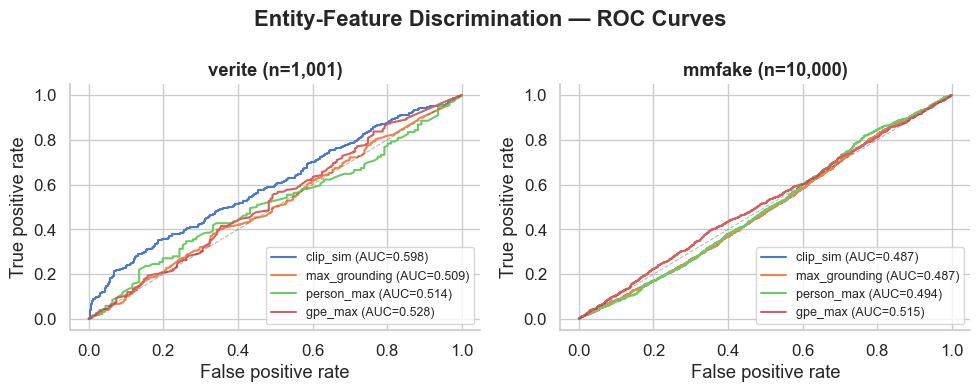

In [10]:
datasets_to_plot = []
for ds in ["newsclippings", "verite", "mmfake"]:
    sub = feat_df[feat_df["dataset"] == ds]
    sub = sub[sub["label"] >= 0]
    if sub["label"].nunique() >= 2 and len(sub) >= 50:
        datasets_to_plot.append((ds, sub))

if datasets_to_plot:
    fig, axes = plt.subplots(1, len(datasets_to_plot), figsize=(5*len(datasets_to_plot), 4))
    if len(datasets_to_plot) == 1: axes = [axes]
    show_features = ["clip_sim", "max_grounding", "person_max", "gpe_max"]

    for ax, (ds, sub) in zip(axes, datasets_to_plot):
        for f in show_features:
            s = sub[["label", f]].dropna()
            if len(s) < 10 or s["label"].nunique() < 2: continue
            y = s["label"].values
            v = -s[f].values if feature_polarity[f] else s[f].values
            fpr, tpr, _ = roc_curve(y, v)
            auc = roc_auc_score(y, v)
            ax.plot(fpr, tpr, label=f"{f} (AUC={auc:.3f})")
        ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=0.8)
        ax.set_title(f"{ds} (n={len(sub):,})", fontweight="bold")
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
        ax.legend(fontsize=9, loc="lower right")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.suptitle("Entity-Feature Discrimination — ROC Curves", fontweight="bold")
    plt.tight_layout()
    savefig("entity_scorer_roc")
    plt.show()
else:
    print("  No datasets have both labels and features — skipping ROC.")

## 10. Feature distributions OOC vs Genuine

  Saved → paper\figures\entity_scorer_feature_distributions.png


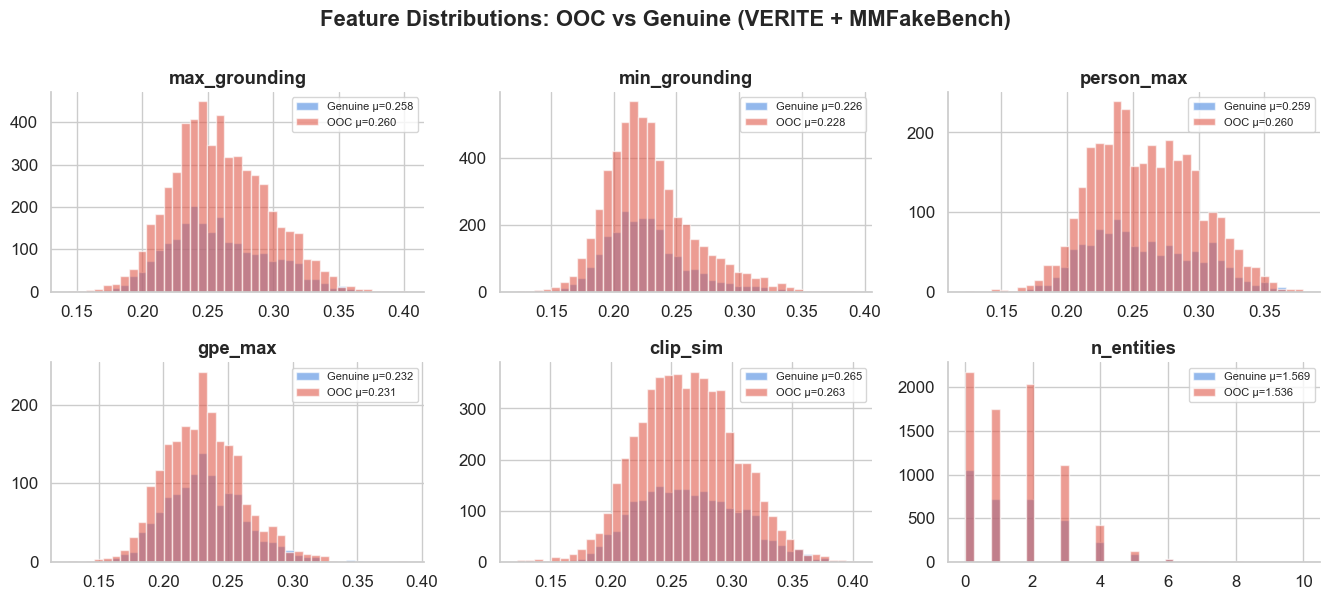

In [11]:
active = feat_df[feat_df["dataset"].isin(["verite", "mmfake"]) & (feat_df["label"] >= 0)].copy()

features_to_show = ["max_grounding", "min_grounding", "person_max", "gpe_max", "clip_sim", "n_entities"]
cols = 3
rows_n = (len(features_to_show) + cols - 1) // cols

fig, axes = plt.subplots(rows_n, cols, figsize=(4.5*cols, 3*rows_n))
axes = axes.flatten() if rows_n*cols > 1 else [axes]

for idx, f in enumerate(features_to_show):
    ax = axes[idx]
    ooc = active[active["label"] == 1][f].dropna()
    gen = active[active["label"] == 0][f].dropna()
    if len(ooc) == 0 or len(gen) == 0:
        ax.set_title(f"{f} — no data"); continue
    lo = min(ooc.min(), gen.min()); hi = max(ooc.max(), gen.max())
    bins = np.linspace(lo, hi, 40) if hi > lo else 10
    ax.hist(gen, bins=bins, alpha=0.6, color="#4B8AE0",
            label=f"Genuine μ={gen.mean():.3f}")
    ax.hist(ooc, bins=bins, alpha=0.6, color="#E05A4B",
            label=f"OOC μ={ooc.mean():.3f}")
    ax.set_title(f, fontweight="bold")
    ax.legend(fontsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for idx in range(len(features_to_show), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Feature Distributions: OOC vs Genuine (VERITE + MMFakeBench)",
             fontweight="bold", y=1.00)
plt.tight_layout()
savefig("entity_scorer_feature_distributions")
plt.show()

## 11. Best single-feature threshold accuracy

In [12]:
def best_threshold_accuracy(sub, feature, flip):
    s = sub[["label", feature]].dropna()
    s = s[s["label"] >= 0]
    if len(s) < 10 or s["label"].nunique() < 2:
        return np.nan, np.nan
    y = s["label"].values
    v = s[feature].values
    ts = np.linspace(v.min(), v.max(), 200)
    best_acc, best_t = 0, ts[0]
    for t in ts:
        pred = (v < t).astype(int) if flip else (v > t).astype(int)
        acc = (pred == y).mean()
        if acc > best_acc: best_acc, best_t = acc, t
    return round(best_acc, 4), round(best_t, 4)

acc_rows = []
for ds in ["newsclippings", "verite", "mmfake"]:
    sub = feat_df[feat_df["dataset"] == ds]
    if sub["label"].nunique() < 2: continue
    for f in feature_names:
        acc, t = best_threshold_accuracy(sub, f, feature_polarity[f])
        if not np.isnan(acc):
            acc_rows.append({"dataset": ds, "feature": f,
                             "best_acc": acc, "best_threshold": t})

acc_df = pd.DataFrame(acc_rows)
if len(acc_df):
    pivot_acc = acc_df.pivot(index="feature", columns="dataset", values="best_acc")
    print("Best single-feature threshold accuracy:")
    print(pivot_acc.round(3).to_string())
    savecsv(acc_df, "entity_scorer_best_threshold_acc")

Best single-feature threshold accuracy:
dataset         mmfake  verite
feature                       
clip_sim         0.711   0.663
gpe_max          0.622   0.676
max_grounding    0.711   0.675
mean_grounding   0.711   0.674
min_grounding    0.711   0.672
n_entities       0.588   0.659
org_max          0.699   0.698
person_max       0.732   0.677
  Saved → paper\tables\entity_scorer_best_threshold_acc.csv


## 12. Done

In [13]:
print("=" * 55)
print("  Entity scorer complete.")
print("=" * 55)
print()
print("  Cache files:")
for f in sorted(FEAT_CACHE.glob("*.pkl")):
    print(f"    {f.name:<45} {f.stat().st_size/1e6:.2f} MB")
print()
print("  Figures (PNG):")
for f in sorted(PAPER_FIGS.glob("entity_scorer_*.png")):
    print(f"    {f.name}")
print()
print("  Tables (CSV):")
for f in sorted(PAPER_TABLES.glob("entity_scorer_*.csv")):
    print(f"    {f.name}")
print()
print("  Features/pair: n_entities, max_grounding, min_grounding, mean_grounding,")
print("                 person_max, gpe_max, org_max, clip_sim")
print()
print("  Next: notebooks/02_stream_a/stream_a_results.ipynb")

  Entity scorer complete.

  Cache files:
    features_all.pkl                              5.11 MB
    features_mmfake.pkl                           0.99 MB
    features_newsclippings_test.pkl               0.34 MB
    features_newsclippings_train.pkl              3.35 MB
    features_newsclippings_val.pkl                0.33 MB
    features_verite.pkl                           0.10 MB

  Figures (PNG):
    entity_scorer_feature_distributions.png
    entity_scorer_roc.png

  Tables (CSV):
    entity_scorer_best_threshold_acc.csv
    entity_scorer_discrimination.csv
    entity_scorer_feature_stats.csv

  Features/pair: n_entities, max_grounding, min_grounding, mean_grounding,
                 person_max, gpe_max, org_max, clip_sim

  Next: notebooks/02_stream_a/stream_a_results.ipynb
